#Лабораторна робота 3
###Варінат 2: Impact of AI on Students
Виконала: Слота Аліна

In [16]:
import pandas as pd
import numpy as np
import sqlite3
import os
import joblib
import matplotlib.pyplot as plt

conn = sqlite3.connect('students.db')
df = pd.read_sql("SELECT * FROM student_impact_encoded", conn)
conn.close()

print("Розмір таблиці:", df.shape)
print("Пропусків у таблиці:", df.isnull().sum().sum())
df.head()

Розмір таблиці: (49019, 27)
Пропусків у таблиці: 0


,Student_ID,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,...,Major_Category_STEM,Institutional_Policy_Allowed_With_Citation,Institutional_Policy_Strict_Ban,Primary_Use_Case_Debugging/Troubleshooting,Primary_Use_Case_Direct_Answer_Generation,Primary_Use_Case_Ideation,Primary_Use_Case_Summarizing_Reading,Prompt_Engineering_Skill_Beginner,Prompt_Engineering_Skill_Intermediate,Prompt_Engineering_Skill_Missing
0,100001,3,-1.583543,1.911410,-1.533307,1,-0.596956,0.824215,0.828608,-1.756430,...,0,1,0,0,0,0,0,1,0,0
1,100002,2,1.447696,-0.953347,1.865805,0,1.059820,-0.277653,2.256391,0.445726,...,0,1,0,0,0,1,0,0,0,0
2,100003,0,0.533787,1.646752,-0.683529,0,-0.165261,0.824215,2.256391,0.112783,...,0,0,1,0,0,0,1,1,0,0
3,100004,3,1.378559,-0.862976,1.016027,0,0.783690,-0.828587,-1.075102,0.959506,...,0,1,0,0,0,0,0,0,1,0
4,100005,1,1.045836,0.101411,1.016027,0,0.262545,0.273281,-0.123247,0.618113,...,1,1,0,1,0,0,0,0,0,0


## Перевірка кодування цільової ознаки

Цільова ознака Burnout_Risk_Level у таблиці збережена числами. Щоб правильно 
рахувати метрики для класу High, потрібно знати, яке саме число йому відповідає. 
Для цього порівнюємо початкову таблицю student_impact (де категорії підписані словами) 
із закодованою таблицею за ключем Student_ID.

In [17]:
conn = sqlite3.connect('students.db')
mapping = pd.read_sql("""
    SELECT DISTINCT a.Burnout_Risk_Level AS original, b.Burnout_Risk_Level AS code
    FROM student_impact a
    JOIN student_impact_encoded b ON a.Student_ID = b.Student_ID
    ORDER BY code
""", conn)
conn.close()
mapping

,original,code
0,Low,0
1,Medium,1
2,High,2


Код класу High збережено у змінну — він буде використовуватись при розрахунку 
метрики recall для цього класу.

## Поділ даних на навчальну та тестову вибірки

Щоб чесно оцінити модель, дані ділимо на дві частини: 80% (навчальна вибірка) 
використовується для тренування, 20% (тестова вибірка) залишається для перевірки.

Використано класичний train_test_split з параметром stratify, який зберігає 
однакове співвідношення класів у навчальній і тестовій вибірках. 
TimeSeriesSplit не застосовувався, оскільки поле timestamp згенероване випадково 
й не відображає реальної часової залежності, а кожен запис описує окремого 
студента. Параметр random_state=42 забезпечує відтворюваність результатів.

In [18]:
from sklearn.model_selection import train_test_split

target = 'Burnout_Risk_Level'
features = [c for c in df.columns if c not in ['Student_ID', 'timestamp', target]]
X = df[features]
y = df[target]
ids = df['Student_ID']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.2, random_state=42, stratify=y
)
print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (39215, 24)
Тестова вибірка: (9804, 24)


## Вибір ознак та перевірка розподілу класів

Цільова змінна - Burnout_Risk_Level. Усі інші колонки, окрім Student_ID 
і timestamp, використовуються як ознаки. 

Student_ID виключено, бо це лише ідентифікатор студента і він не несе  змістовної інформації для прогнозу (використовується тільки для зв'язку результатів із записами в базі).
timestamp виключено, бо це випадкова дата, згенерована в лабораторній 1 для майбутнього аналізу в часі, і реального зв'язку з вигоранням вона не має.

Також перевіряємо, як розподілені класи цільової змінної — це важливо 
для вибору метрик і для рішення щодо балансування класів.

In [19]:

print("Кількість ознак:", len(features))

print("\nРозподіл класів, %:")
print((df[target].value_counts(normalize=True).sort_index() * 100).round(1))

Кількість ознак: 24

Розподіл класів, %:
Burnout_Risk_Level
0    32.8
1    42.2
2    25.0
Name: proportion, dtype: float64


## Вибір техніки моделювання

Цільова ознака Burnout_Risk_Level має три категорії (Low, Medium, High), 
тому задача є багатокласовою класифікацією. Регресія не підходить, 
оскільки ми прогнозуємо не число, а категорію ризику. Кластеризація теж 
не підходить, бо в даних є готові мітки, на яких модель можна навчити (навчання з учителем).

Такий підхід відповідає бізнес-цілі замовника — заздалегідь виявляти студентів 
з підвищеним ризиком вигорання, щоб університет міг вчасно запропонувати підтримку.

## Модельні припущення

Для порівняння обрано три моделі: логістичну регресію, дерево рішень 
і випадковий ліс.

Логістична регресія припускає приблизно лінійний зв'язок між ознаками та логарифмом шансів класу, а також відсутність сильної мультиколінеарності (ознаки не повинні майже повністю дублювати одна одну). Масштабування числових ознак допомагає цій моделі.

Дерево рішень не вимагає лінійності й масштабування та стійке до викидів, але схильне до перенавчання, коли дерево занадто глибоко підлаштовується під навчальні дані.

Випадковий ліс об'єднує багато дерев, що зменшує перенавчання, і теж не потребує жорстких припущень про розподіл даних.

Для всіх моделей важливі незалежність спостережень (кожен студент — окремий запис) і достатня збалансованість класів.

In [20]:
print("Student_ID унікальний:", df['Student_ID'].is_unique)

corr = X_train.corr().abs()
corr_nd = corr.where(~np.eye(len(corr), dtype=bool))
print("Максимальна кореляція між ознаками:", round(corr_nd.max().max(), 3))
print(corr_nd.unstack().dropna().sort_values(ascending=False).head(6).round(3))  # кожна пара двічі

Student_ID унікальний: True
Максимальна кореляція між ознаками: 0.718
Pre_Semester_GPA                       Post_Semester_GPA                        0.718
Post_Semester_GPA                      Pre_Semester_GPA                         0.718
Weekly_GenAI_Hours                     Perceived_AI_Dependency                  0.607
Perceived_AI_Dependency                Weekly_GenAI_Hours                       0.607
Prompt_Engineering_Skill_Beginner      Prompt_Engineering_Skill_Intermediate    0.526
Prompt_Engineering_Skill_Intermediate  Prompt_Engineering_Skill_Beginner        0.526
dtype: float64


## Вибір метрик оцінки

Обрано три метрики:

Accuracy — частка правильних передбачень. Проста й зрозуміла, дає загальну картину якості моделі.

F1-score  — середнє значення F1 по всіх трьох класах. Враховує і точність (precision), і повноту (recall) та не дозволяє моделі мати високу оцінку лише за рахунок найбільшого класу.

Recall для класу High — частка студентів із реально високим ризиком, яких модель знайшла. Це найважливіша метрика для бізнес-цілі: пропустити студента у критичному стані (false negative) значно гірше, ніж зайвий раз перевірити студента без проблем.


In [21]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

def calc_metrics(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'f1_macro': f1_score(y_true, y_pred, average='macro'),
        'recall_high': recall_score(y_true, y_pred, labels=[HIGH_CODE], average=None)[0]
    }

## Підготовка до тренування та логування результатів у базу даних

Допоміжні функції для збереження результатів у базі даних:

- log_model — для кожної моделі робить передбачення на навчальній і тестовій вибірках, рахує метрики та додає результати до списків. Кожен запис має мітки: назва моделі, етап (baseline — до оптимізації, tuned — після) і джерело даних (source = «train» або «test»).
- save_logs — записує накопичені результати в таблиці predictions(передбачення для кожного студента) та model_metrics (метрики моделей) у базі даних.

In [22]:
pred_frames = []
metric_rows = []

def log_model(name, model, stage, params=''):
    for source, Xs, ys, ids_ in [('train', X_train, y_train, id_train),
                                  ('test', X_test, y_test, id_test)]:
        y_pred = model.predict(Xs)
        pred_frames.append(pd.DataFrame({
            'Student_ID': ids_.values, 'model_name': name, 'stage': stage,
            'source': source, 'y_true': ys.values, 'y_pred': y_pred
        }))
        metric_rows.append({
            'model_name': name, 'stage': stage, 'source': source,
            **calc_metrics(ys, y_pred), 'best_params': params
        })

def save_logs():
    conn = sqlite3.connect('students.db')
    pd.concat(pred_frames, ignore_index=True).to_sql('predictions', conn, if_exists='replace', index=False)
    pd.DataFrame(metric_rows).to_sql('model_metrics', conn, if_exists='replace', index=False)
    conn.close()
    print("Таблиці predictions і model_metrics збережено в students.db")

## Метрика та метод оптимізації гіперпараметрів

Гіперпараметри — це налаштування моделі, які задаються до навчання 
(наприклад, кількість дерев чи їх глибина). Від них залежить якість моделі, 
тому їх потрібно підбирати.

Метрика для оптимізації: F1-score (macro), оскільки вона враховує якість прогнозу по всіх трьох класах одночасно.

Метод: RandomizedSearchCV — випробовує випадкові комбінації параметрів і працює значно швидше за повний перебір (GridSearchCV) при близькій якості. Використано 3-кратну крос-валідацію (навчальні дані тричі ділиться на частини, щоб оцінка була надійнішою) та 10 випадкових комбінацій.

Підбираються такі параметри Random Forest:
- n_estimators (кількість дерев): 100, 200, 300;
- max_depth (максимальна глибина дерева): 5, 10, 15 або без обмеження;
- min_samples_split (мінімум об'єктів для розбиття вузла): 2, 5, 10;
- min_samples_leaf (мінімум об'єктів у листі): 1, 2, 4.

Метрику F1 (macro) обрано цільовою, бо вона враховує всі три класи; recall для класу High не використано як цільову метрику, але контролюється поруч, адже він найважливіший для бізнес-цілі. Для захисту від перенавчання застосовано крос-валідацію.

## Тренування трьох моделей


1. Logistic Regression — проста лінійна модель, швидка й добре інтерпретована.
2. Decision Tree (max_depth=8) — одне дерево рішень з обмеженою глибиною, щоб зменшити ризик перенавчання.
3. Random Forest** (100 дерев) — ансамбль дерев, зазвичай найточніший з трьох.

Метод fit() виконує навчання на навчальній вибірці. Після кожного навчання 
результати записуються в базу даних (етап «baseline» — до оптимізації).

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

HIGH_CODE = 2

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    log_model(name, model, 'baseline')

save_logs()
pd.DataFrame(metric_rows).round(3)

Таблиці predictions і model_metrics збережено в students.db


,model_name,stage,source,accuracy,f1_macro,recall_high,best_params
0,Logistic Regression,baseline,train,0.531,0.530,0.468,
1,Logistic Regression,baseline,test,0.532,0.531,0.477,
2,Decision Tree,baseline,train,0.556,0.559,0.508,
3,Decision Tree,baseline,test,0.515,0.520,0.490,
4,Random Forest,baseline,train,1.000,1.000,1.000,
5,Random Forest,baseline,test,0.517,0.520,0.477,


## Обробка незбалансованих класів

За розподілом класів, отриманим на початку роботи, перевіряємо, чи є дисбаланс. Якщо один із класів помітно переважає, модель може «ігнорувати» рідкісний клас і все одно мати високу accuracy. Для боротьби з цим обрано параметр class_weight='balanced' — він автоматично збільшує вагу помилок на рідкісних класах. Цей метод обрано замість SMOTE або oversampling, тому що він не створює штучних записів і не змінює самі дані.

Навчаємо додаткову модель Random Forest з балансуванням і додаємо її до порівняння.

In [24]:
rf_bal = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                random_state=42, n_jobs=-1)
rf_bal.fit(X_train, y_train)
fitted['Random Forest (balanced)'] = rf_bal
log_model('Random Forest (balanced)', rf_bal, 'baseline')

save_logs()
pd.DataFrame(metric_rows).round(3)

Таблиці predictions і model_metrics збережено в students.db


,model_name,stage,source,accuracy,f1_macro,recall_high,best_params
0,Logistic Regression,baseline,train,0.531,0.530,0.468,
1,Logistic Regression,baseline,test,0.532,0.531,0.477,
2,Decision Tree,baseline,train,0.556,0.559,0.508,
3,Decision Tree,baseline,test,0.515,0.520,0.490,
4,Random Forest,baseline,train,1.000,1.000,1.000,
5,Random Forest,baseline,test,0.517,0.520,0.477,
6,Random Forest (balanced),baseline,train,1.000,1.000,1.000,
7,Random Forest (balanced),baseline,test,0.513,0.522,0.569,


In [25]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=10, scoring='f1_macro', cv=3,
    random_state=42, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)

print("Найкращі параметри:", search.best_params_)
print("Найкращий F1 macro (крос-валідація):", round(search.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Найкращі параметри: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 15}
Найкращий F1 macro (крос-валідація): 0.5272


## Вибір найкращої моделі

Порівнюємо всі навчені моделі за метриками на тестовій вибірці, оскільки саме вона показує, як модель працює на нових даних. Таблиця відсортована за F1-score  від найкращої до найгіршої. Також порівнюємо результати на навчальній і тестовій вибірках: велика різниця між ними вказує на перенавчання моделі.

In [26]:
results = pd.DataFrame(metric_rows)
test_all = results[results['source'] == 'test'].copy()
test_all['model'] = test_all['model_name'] + ' (' + test_all['stage'] + ')'
display(test_all.sort_values('f1_macro', ascending=False)[['model','accuracy','f1_macro','recall_high']].round(3))

pivot = results.pivot_table(index=['model_name','stage'], columns='source', values='f1_macro').round(3)
pivot['розрив train-test'] = (pivot['train'] - pivot['test']).round(3)
pivot

,model,accuracy,f1_macro,recall_high
1,Logistic Regression (baseline),0.532,0.531,0.477
7,Random Forest (balanced) (baseline),0.513,0.522,0.569
3,Decision Tree (baseline),0.515,0.520,0.490
5,Random Forest (baseline),0.517,0.520,0.477


,source,test,train,розрив train-test
model_name,stage,,,
Decision Tree,baseline,0.520,0.559,0.039
Logistic Regression,baseline,0.531,0.530,-0.001
Random Forest,baseline,0.520,1.000,0.480
Random Forest (balanced),baseline,0.522,1.000,0.478


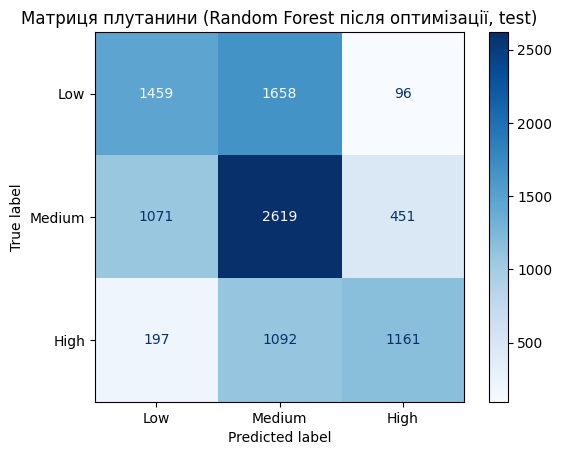

              precision    recall  f1-score   support

         Low      0.535     0.454     0.491      3213
      Medium      0.488     0.632     0.551      4141
        High      0.680     0.474     0.558      2450

    accuracy                          0.534      9804
   macro avg      0.568     0.520     0.533      9804
weighted avg      0.551     0.534     0.533      9804



In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

best_model = search.best_estimator_
y_pred_test = best_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test,
    display_labels=['Low', 'Medium', 'High'], cmap='Blues')
plt.title('Матриця плутанини (Random Forest після оптимізації, test)')
plt.show()
print(classification_report(y_test, y_pred_test, target_names=['Low','Medium','High'], digits=3))

Для порівняння: тривіальний прогноз «завжди Medium» дає accuracy близько 0,42 (частка найбільшого класу). Усі моделі краще за нього, але приріст невеликий, приблизно 10–11 процентних пунктів.

Різниця між двома найкращими моделями (логістична регресія й оптимізований ліс) за F1 становить лише 0,002, тобто вони практично рівноцінні. Для практичних робіт вищу метрику вважаємо достатньою підставою для вибору, тому найкращою обрано Random Forest після оптимізації: він має найвищі accuracy (0,534) і F1 macro (0,533). Логістична регресія стабільна (train приблизно дорівнює test) і простіша для інтерпретації, а Decision Tree має найвищий recall для High (0,490), але нижчу загальну якість.

Оптимізацію виконано саме для Random Forest, бо він мав найбільший простір для покращення: до налаштування він повністю запам'ятовував навчальні дані (F1 macro 1,000 на train проти 0,520 на тесті), що відповідає стану перенавчання. Логістична регресія такого розриву не має.

## Таблиця експериментів оптимізації

In [28]:
cv_table = pd.DataFrame(search.cv_results_)[['param_n_estimators','param_max_depth',
    'param_min_samples_split','param_min_samples_leaf','mean_test_score','std_test_score','rank_test_score']]
cv_table.sort_values('rank_test_score').round(4)

,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,300,15,5,4,0.5272,0.0035,1
5,200,15,5,2,0.5272,0.0043,2
4,300,15,10,1,0.5259,0.0032,3
7,100,10,2,4,0.5251,0.0046,4
6,100,10,5,1,0.5248,0.0026,5
8,300,None,5,2,0.5233,0.0038,6
3,300,None,2,1,0.5223,0.0055,7
2,200,5,5,1,0.4971,0.0015,8
1,200,5,2,2,0.4967,0.0016,9
9,300,5,2,2,0.4955,0.0025,10


## 8. Аналіз важливості ознак

Щоб зрозуміти, які характеристики студента найсильніше впливають на прогноз вигорання, використовуємо атрибут feature_importances_ моделі Random Forest. Він показує, наскільки кожна ознака допомагала моделі приймати рішення. 

Weekly_GenAI_Hours                            0.1725
Traditional_Study_Hours                       0.1080
Pre_Semester_GPA                              0.1051
Skill_Retention_Score                         0.1050
Post_Semester_GPA                             0.0981
Perceived_AI_Dependency                       0.0693
Anxiety_Level_During_Exams                    0.0612
Tool_Diversity                                0.0453
Year_of_Study                                 0.0446
Institutional_Policy_Allowed_With_Citation    0.0171
dtype: float64


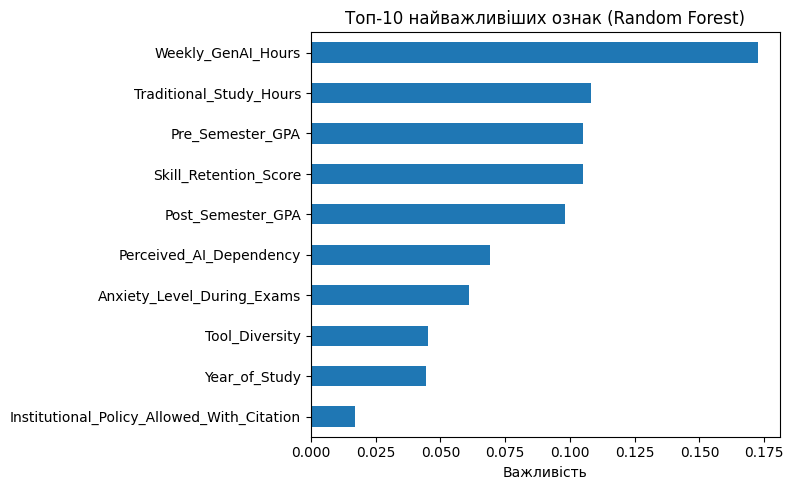

In [29]:
rf = fitted['Random Forest']
importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print(importance.head(10).round(4))

importance.head(10).sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Топ-10 найважливіших ознак (Random Forest)')
plt.xlabel('Важливість')
plt.tight_layout()
plt.show()

За feature_importances_ найвпливовішою ознакою є Weekly_GenAI_Hours (0,1725), майже вдвічі більше за наступні: Traditional_Study_Hours (0,1080), Pre_Semester_GPA (0,1051), Skill_Retention_Score (0,1050) і Post_Semester_GPA (0,0981). Середній вплив мають Perceived_AI_Dependency (0,0693) та Anxiety_Level_During_Exams (0,0612), менший — Tool_Diversity і Year_of_Study (близько 0,045). Топ-10 ознак разом дають приблизно 83% сумарної важливості.

Отже, ризик вигорання найкраще пояснюють інтенсивність використання GenAI, час традиційного навчання та показники успішності, що узгоджується з початковою гіпотезою дослідження. Ознаки напряму навчання, типу використання AI та політики закладу мають малу вагу (усі окрім Institutional_Policy_Allowed_With_Citation нижчі за 0,017) і є кандидатами на виключення в подальшому.

Важливість ознак показує внесок у прогноз моделі, а не причинно-наслідковий зв'язок. Також ці значення отримано з моделі до оптимізації, яка перенавчалась.

## 11–12. Збереження результатів оптимізації

Беремо модель із найкращими знайденими параметрами і записуємо її метрики 
(етап «tuned») у ті самі таблиці predictions та model_metrics. Завдяки цьому 
в model_metrics поряд стоять результати до оптимізації (baseline) і після (tuned), 
і їх можна напряму порівняти. Додатково виводимо метрики оптимізованої моделі 
на навчальних і тестових даних.

In [30]:
best_model = search.best_estimator_
log_model('Random Forest', best_model, 'tuned', str(search.best_params_))
save_logs()

final = pd.DataFrame(metric_rows)
final[final['model_name'] == 'Random Forest'].round(3)

Таблиці predictions і model_metrics збережено в students.db


,model_name,stage,source,accuracy,f1_macro,recall_high,best_params
4,Random Forest,baseline,train,1.000,1.000,1.000,
5,Random Forest,baseline,test,0.517,0.520,0.477,
8,Random Forest,tuned,train,0.780,0.772,0.629,"{'n_estimators': 300, 'min_samples_split': 5, ..."
9,Random Forest,tuned,test,0.534,0.533,0.474,"{'n_estimators': 300, 'min_samples_split': 5, ..."


## 12. Збереження моделі у файл

Оптимізовану модель серіалізуємо (зберігаємо у файл) за допомогою бібліотеки joblib у папку models/. Завдяки цьому модель можна завантажити пізніше й використовувати для прогнозів без повторного навчання. Для коректної роботи з новими студентами також потрібен збережений раніше масштабувальник my_standard_scaler.pkl.

In [31]:
os.makedirs('models', exist_ok=True)
joblib.dump(best_model, 'models/best_model.pkl')
print("Модель збережено: models/best_model.pkl")

Модель збережено: models/best_model.pkl


## 13. Результати оптимізації

Після підбору гіперпараметрів (RandomizedSearchCV, 10 комбінацій, 3-кратна крос-валідація, метрика F1 macro) найкращими виявились: n_estimators = 300, max_depth = 15, min_samples_split = 5, min_samples_leaf = 4. F1 macro за крос-валідацією становить 0,5272, а на тестовій вибірці 0,533. Ці значення близькі, тобто оцінка стабільна і підбір не підлаштовувався під тест.

Зміни на тестовій вибірці: accuracy 0,517 → 0,534, F1 macro 0,520 → 0,533, recall High 0,477 → 0,474 (практично без змін). На навчальній вибірці F1 macro знизилась з 1,000 до 0,772, а accuracy з 1,000 до 0,780, тобто модель стала менше запам'ятовувати дані. Розрив між train і test за F1 скоротився з 0,480 до 0,239: перенавчання зменшено, але не усунуто.

Найбільший вплив, найімовірніше, мали параметри, що обмежують складність дерев: max_depth = 15 (замість необмеженої глибини) і min_samples_leaf = 4 (у листі не менше 4 студентів). Вони не дозволяють дереву підлаштовуватись під окремих студентів, про що свідчить зниження метрик на навчальній вибірці. Загальний приріст на тесті невеликий (близько 1–2 п.п.), тому основне обмеження полягає не в налаштуванні моделі, а в інформативності самих даних.

## 14. Обробка незбалансованих класів

Розподіл класів Low / Medium / High становить 32,8% / 42,2% / 25,0%. Дисбаланс помірний: найбільший клас лише в 1,7 раза переважає найменший. Однак клас High найважливіший для бізнес-цілі й водночас найменший, тому перевірено ваги класів. Крім того, застосовано stratify при поділі даних, а якість оцінювалась метриками F1 macro та recall High, а не лише accuracy.

Обрано class_weight='balanced' замість SMOTE, oversampling чи undersampling, бо він не змінює дані, не створює штучних студентів і не видаляє записи. Результат для Random Forest (balanced) на тесті: accuracy 0,520, F1 macro 0,519, recall High 0,460, тоді як без ваг було 0,517 / 0,520 / 0,477. Покращення немає, recall High навіть знизився. Імовірна причина: головна проблема — перенавчання лісу (на train 1,000), а не дисбаланс; повністю вирощені дерева ідеально підлаштовуються під навчальні дані незалежно від ваг. Тому ваги класів у підсумкову модель не включено.

## 15. Підсумкові пояснення

**Чому обрано саме цю модель.** Random Forest після оптимізації має найвищі accuracy (0,534) і F1 macro (0,533) на тесті, працює з числовими й закодованими категоріальними ознаками без жорстких припущень і стійкий до викидів. Також він дає важливість ознак, що важливо для пояснення результатів. Недолік — вища складність і гірша інтерпретованість порівняно з логістичною регресією, яка має майже таку саму якість (F1 0,531), тому за потреби простоти вона є прийнятною альтернативою.

**Як аналіз важливості ознак вплинув на розуміння задачі.** Він показав, що ризик вигорання найсильніше пов'язаний з кількістю годин використання GenAI на тиждень, часом традиційного навчання та показниками успішності. Тобто для університету ключовими сигналами є інтенсивність використання AI і баланс між AI та самостійним навчанням. Напрям навчання та політика закладу майже не впливають. Водночас це не доводить причинності.

**Як модель показала себе на навчальних і тестових даних.** Випадковий ліс до оптимізації повністю запам'ятовував навчальні дані (F1 1,000 проти 0,520 на тесті). Після оптимізації розрив зменшився (0,772 проти 0,533), але лишається. Логістична регресія стабільна (0,530 і 0,531), проте на рівні близько 0,53. Усі моделі перевершують тривіальний прогноз (accuracy близько 0,42), але загальна якість помірна. Те, що і лінійна, і нелінійні моделі впираються приблизно в 0,53, вказує на слабкий зв'язок між ознаками та цільовою змінною.

**Наскільки вона готова до впровадження.** Модель ще не готова до самостійного використання. По-перше, recall для High становить 0,474, тобто більше половини студентів із високим ризиком модель пропускає. По-друге, ознаки Post_Semester_GPA і Skill_Retention_Score вимірюються після семестру, тому для раннього попередження вони недоступні, і модель без них, імовірно, буде слабшою. По-третє, якщо масштабувальник у ЛР2 навчався на всьому датасеті до поділу, це дрібний витік інформації, який краще усунути через Pipeline. По-четверте, дані потрібно перевірити на реальних студентах. Технічно все підготовлено: модель збережена у models/best_model.pkl, масштабувальник у my_standard_scaler.pkl, прогнози й метрики записано в таблиці predictions та model_metrics. У виробництві потрібен моніторинг дрейфу даних і регулярне перенавчання, а прогноз має використовуватись лише як допоміжний інструмент, а не єдина підстава для рішень щодо студента.

# Висновок

У цій лабораторній роботі я навчилась будувати модель для прогнозування рівня ризику вигорання студентів. Я обрала багатокласову класифікацію, поділила дані на навчальну й тестову вибірки та навчила три моделі: логістичну регресію, дерево рішень і випадковий ліс. Результати я записувала в таблиці predictions та model_metrics у базі даних, а оцінювала моделі за accuracy, F1-score та recall для класу High.

Я побачила, що випадковий ліс без налаштувань перенавчається: на навчальних даних точність 100%, а на тестових лише близько 52%. Після підбору гіперпараметрів через RandomizedSearchCV перенавчання зменшилось, F1-score на тесті зріс з 0,520 до 0,533, і цю модель я зберегла у файл best_model.pkl. Також я навчилась дивитись важливість ознак: найважливішою виявилась кількість годин використання GenAI на тиждень.

Точність моделей близько 53%, тож для реального використання їх ще треба покращувати. Але ця робота показала мені весь шлях від підготовлених даних до збереженої моделі та те, що навіть налаштована модель не дає високої точності, якщо дані слабко пов'язані з цільовою ознакою.